# Прогнозирование уровня аэродинамического шума по параметрам воздушного потока
Владислав Вейгандт · Итоговый проект по физике

**Цель** — по условиям обтекания профиля NACA 0012 и частоте оценить уровень аэродинамического шума. Проверяем гипотезу, что нелинейная модель точнее линейной регрессии на режимах обтекания, которые обе модели впервые видят на тесте.

## Откуда берётся шум

При обтекании профиля у его поверхности образуется пограничный слой. Пульсации давления в турбулентном пограничном слое, проходя через заднюю кромку, излучают звук. В зависимости от режима вклад в шум также могут вносить отрыв потока и вихреобразование. Из-за этого спектр меняется со скоростью потока, углом атаки и состоянием пограничного слоя. [NASA RP-1218](https://ntrs.nasa.gov/citations/19890016302)

Уровень звукового давления обычного звука определяется как $L_p=20\log_{10}(p_{\mathrm{rms}}/p_0)$, где $p_0=20\,\mu\text{Па}$ для воздуха. В этой работе целевая величина — **масштабированный уровень звукового давления** из набора NASA, в дБ для заданной частоты. По набору частот при фиксированном режиме можно построить прогноз спектра.

| Вход | Смысл | Единица |
|---|---|---|
| $f$ | Частота | Гц |
| $\alpha$ | Угол атаки | ° |
| $c$ | Длина хорды профиля | м |
| $U$ | Скорость набегающего потока | м/с |
| $\delta^*$ | Толщина вытеснения пограничного слоя на стороне разрежения | м |

Толщина вытеснения характеризует дефицит расхода из-за замедления воздуха у поверхности. Для вычисления прогноза её значение должно быть известно. Эту величину используем также для числа Струхаля $St=f\delta^*/U$. Оно показывает отношение времени переноса потоком на характерную длину $\delta^*$ к периоду колебаний $1/f$. Сеть получает этот безразмерный параметр как дополнительный признак, вычисляемый из пяти входов.

In [1]:
from pathlib import Path
import numpy as np
from airfoil_noise import DATA, FEATURES, OUTPUT, predict, split_by_condition, train

data = np.loadtxt(DATA)
masks, _, group_splits = split_by_condition(data)
assert np.all(np.sum(masks, axis=0) == 1)
assert sum(map(len, group_splits)) == len(np.unique(np.concatenate(group_splits)))
print(f"{len(data)} измерения, {sum(map(len, group_splits))} режимов обтекания")
for name, low, high in zip((*FEATURES, "scaled_spl_db"), data.min(axis=0), data.max(axis=0)):
    print(f"{name:<17} {low:g} … {high:g}")

1503 измерения, 106 режимов обтекания
frequency_hz      200 … 20000
angle_deg         0 … 22.2
chord_m           0.0254 … 0.3048
velocity_m_s      31.7 … 71.3
thickness_m       0.000400682 … 0.0584113
scaled_spl_db     103.38 … 140.987


## Обучение и проверка

За один режим считаем все записи с одинаковыми $\alpha$, $c$ и $U$. Частоты одного режима всегда остаются в одной выборке. Это исключает ситуацию, когда модель учится на части спектра, а на тесте видит оставшиеся точки того же режима.

К четырём положительным входным величинам применяется $\log_{10}$, затем модель стандартизирует признаки по обучающей выборке. Полносвязная сеть имеет размеры слоёв $6\to64\to64\to32\to1$ и активацию SiLU. Для обучения используются AdamW и среднеквадратичная ошибка по стандартизованной цели. Эпоху выбираем по минимальной средней абсолютной ошибке на валидации. На тесте сравниваем сеть со средним значением на обучении и линейной регрессией по пяти преобразованным признакам. MAE показывает типичный масштаб абсолютной ошибки, а RMSE сильнее учитывает большие промахи.

In [2]:
metrics = train()
for split, info in metrics["split"].items():
    print(f"{split:>10}: {info['conditions']:>2} режимов, {info['rows']:>3} измерений")
print(f"Выбранная эпоха: {metrics['best_epoch']}")
print("\nМодель        MAE (дБ)   RMSE (дБ)       R²")
for label in ("constant", "linear", "pytorch"):
    row = metrics[label]
    print(f"{label:<12} {row['mae_db']:>9.2f} {row['rmse_db']:>11.2f} {row['r2']:>9.3f}")

     train: 64 режимов, 910 измерений
validation: 21 режимов, 307 измерений
      test: 21 режимов, 286 измерений
Выбранная эпоха: 158

Модель        MAE (дБ)   RMSE (дБ)       R²
constant          5.66        6.95    -0.020
linear            3.77        4.80     0.514
pytorch           1.67        2.62     0.856


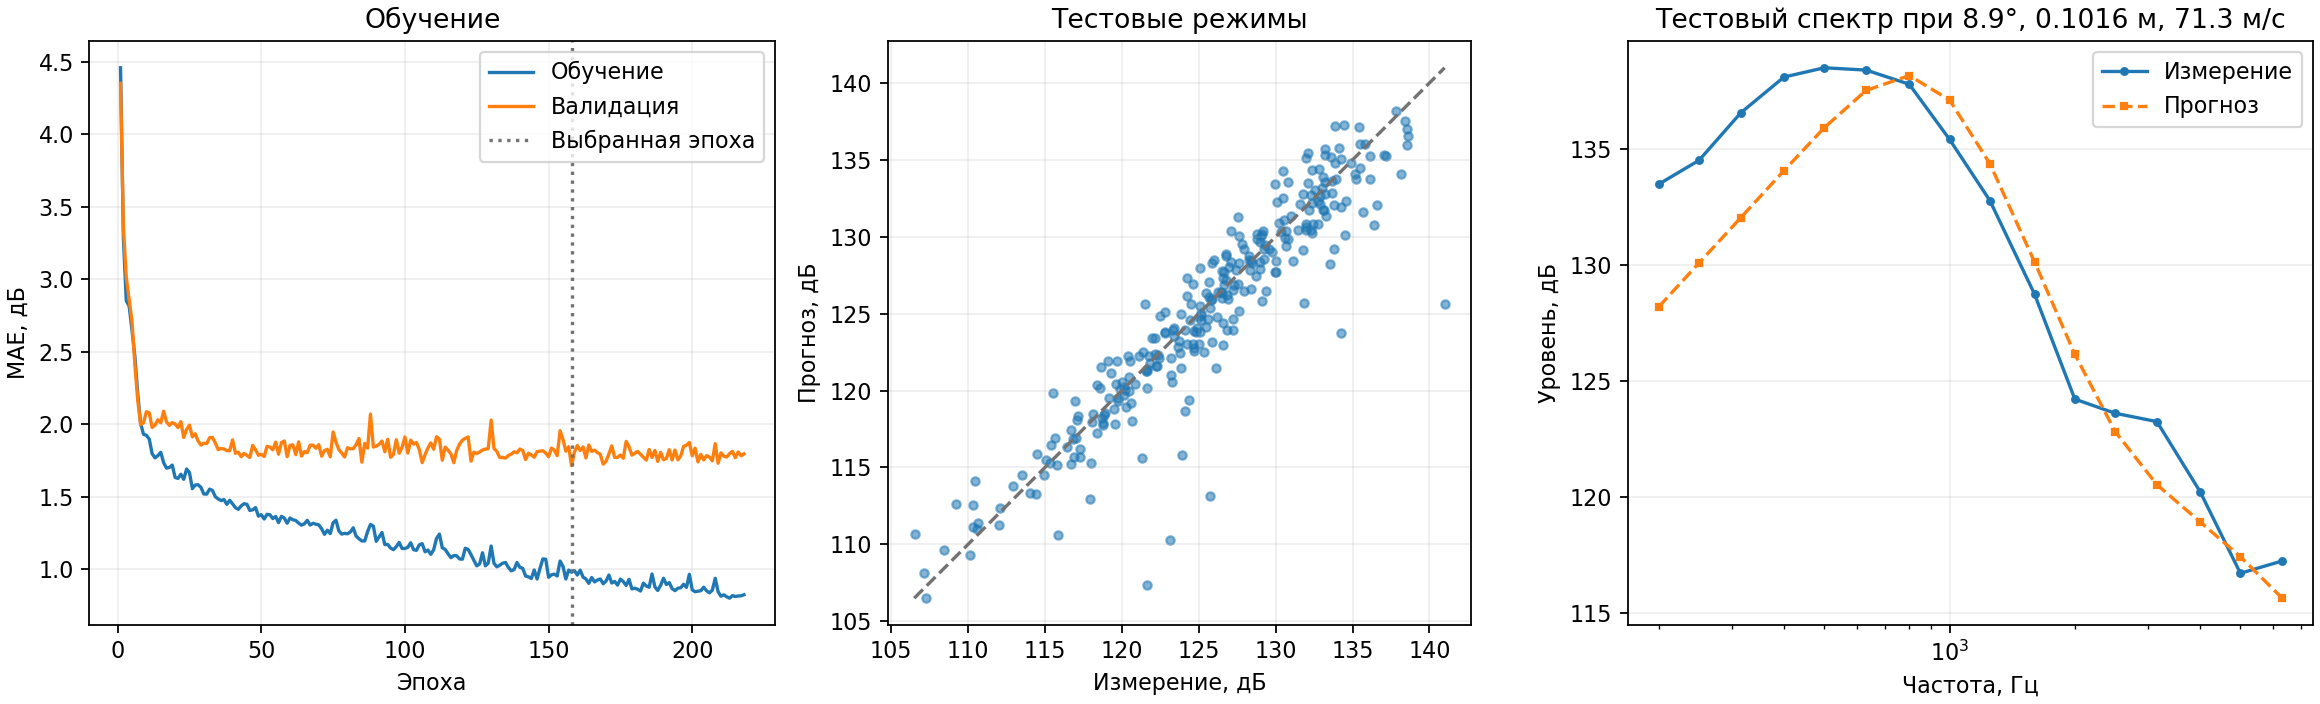

Пик, измерение: 500 Гц, 138.52 дБ
Пик, прогноз: 800 Гц, 138.19 дБ
Максимальная ошибка на тесте: 15.35 дБ


In [3]:
from IPython.display import Image, display

display(Image(filename=OUTPUT / "evaluation.png", width=1150))

test = np.loadtxt(OUTPUT / "test_predictions.csv", delimiter=",", skiprows=1)
condition = (test[:, 1:4] == [8.9, 0.1016, 71.3]).all(axis=1)
spectrum = test[condition]
for column, label in [(5, "измерение"), (6, "прогноз")]:
    peak = spectrum[spectrum[:, column].argmax()]
    print(f"Пик, {label}: {peak[0]:g} Гц, {peak[column]:.2f} дБ")
errors = np.abs(test[:, 5] - test[:, 6])
print(f"Максимальная ошибка на тесте: {errors.max():.2f} дБ")

## Прогноз по пяти параметрам

В примере используется одна точка из отложенного режима. Поменяйте значения в списке, чтобы рассчитать прогноз для своих входных данных.

In [4]:
parameters = [800, 1.5, 0.3048, 71.3, 0.00336729]
level_db, outside_training_ranges = predict(parameters)
print(f"Прогноз: {level_db.item():.2f} дБ")
print(f"Измерение для исходного примера: {test[0, 5]:.2f} дБ")
if outside_training_ranges.item():
    print("Один или несколько параметров выходят за диапазон обучающих данных.")

Прогноз: 128.34 дБ
Измерение для исходного примера: 127.12 дБ


## Вывод

На отложенных 286 измерениях из 21 режима нейросеть показала MAE **1,67 дБ**, а линейная модель — **3,77 дБ**. Для показанного тестового режима сеть воспроизводит широкую область максимума и спад на высоких частотах. Сдвиг пика и отдельные большие ошибки ограничивают применимость модели там, где требуется точно найти частоту максимума или гарантировать малую ошибку на каждой частоте.

Оценка относится к одному разбиению измерений профиля NACA 0012, полученных в аэродинамической трубе. Точность для другой геометрии, другого экспериментального стенда или скоростей за пределами обучающего диапазона потребует отдельной проверки. Попадание каждого параметра в обучающий диапазон само по себе не гарантирует, что их комбинация встречалась при обучении.

**Данные.** Brooks, T., Pope, D., & Marcolini, M. (1989). *Airfoil Self-Noise* [Dataset]. UCI Machine Learning Repository. [DOI 10.24432/C5VW2C](https://doi.org/10.24432/C5VW2C), лицензия [CC BY 4.0](https://creativecommons.org/licenses/by/4.0/).